# Assignment 3 - Step 2: Classical Neural Networks for Text Classification

In this notebook I train two classical neural network models for multi-label text classification.

The assignment requires two models for this step:
- one model with Conv1D layers,
- one model with LSTM layers.

The task is multi-label classification, which means that one text can belong to more than one category at the same time. Because of that, I use a sigmoid output layer and binary cross-entropy loss.

I use the chunk-based dataset prepared in Step 1. This keeps the input size manageable and allows both models to train on the same data. Using the same train, validation, and test splits also makes the comparison between the two models fair.

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import accuracy_score, f1_score, hamming_loss, precision_score, recall_score
from sklearn.preprocessing import MultiLabelBinarizer
from tensorflow import keras
from tensorflow.keras import layers

In [3]:
SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path.cwd()
PREP_DIR = PROJECT_DIR / "data/processed/"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

CHUNKS_PATH = PREP_DIR / "chunks_prepared.parquet"

# Hardware-aware settings
MAX_TRAIN_SAMPLES = 20000
MAX_VAL_SAMPLES = 4000
MAX_TEST_SAMPLES = 4000

VOCAB_SIZE = 30000
SEQ_LENGTH = 256
EMBEDDING_DIM = 128

BATCH_SIZE = 64
EPOCHS = 20

## Load the prepared chunk dataset

I use the chunk-level dataset from Step 1. This is the most practical input for Step 2 because full books are too long for direct training.

I also keep a maximum number of chunks per split. This keeps training time reasonable while still leaving enough data for comparison.

In [4]:
chunks_df = pd.read_parquet(CHUNKS_PATH)

chunks_df["labels"] = chunks_df["labels"].apply(json.loads)

print(chunks_df.shape)
chunks_df.head()

(18981, 9)


,book_id,chunk_id,text_id,title,authors,split,labels,text_chunk,chunk_words
0,25698,25698_0,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],(This file was produced from images generously...,256
1,25698,25698_1,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],"own good man To his clean hearth, his pipe, an...",256
2,25698,25698_2,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],"rosy children round him press, Eager to share ...",256
3,25698,25698_3,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],Sometimes with beasts compelled to herd; A fis...,256
4,25698,25698_4,25698,"Think Before You Speak; Or, The Three Wishes","Dorset, Catherine Ann Turner, 1750?-1817?; Lep...",test,[Category: Children & Young Adult Reading],you name! Think what will best your state amen...,256


In [5]:
train_df = chunks_df[chunks_df["split"] == "train"].copy()
val_df = chunks_df[chunks_df["split"] == "val"].copy()
test_df = chunks_df[chunks_df["split"] == "test"].copy()

if len(train_df) > MAX_TRAIN_SAMPLES:
    train_df = train_df.sample(MAX_TRAIN_SAMPLES, random_state=SEED)

if len(val_df) > MAX_VAL_SAMPLES:
    val_df = val_df.sample(MAX_VAL_SAMPLES, random_state=SEED)

if len(test_df) > MAX_TEST_SAMPLES:
    test_df = test_df.sample(MAX_TEST_SAMPLES, random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

Train: (13302, 9)
Val: (2856, 9)
Test: (2823, 9)


## Prepare labels and text arrays

For multi-label classification I transform the list of labels into a multi-hot matrix.  
This allows each text chunk to belong to several classes at the same time.

In [6]:
mlb = MultiLabelBinarizer()

y_train = mlb.fit_transform(train_df["labels"])
y_val = mlb.transform(val_df["labels"])
y_test = mlb.transform(test_df["labels"])

label_names = list(mlb.classes_)
num_labels = len(label_names)

x_train = train_df["text_chunk"].astype(str).to_numpy()
x_val = val_df["text_chunk"].astype(str).to_numpy()
x_test = test_df["text_chunk"].astype(str).to_numpy()

print("Number of labels:", num_labels)
print(label_names)

Number of labels: 10
['Category: Adventure', 'Category: American Literature', 'Category: Biographies', 'Category: British Literature', 'Category: Children & Young Adult Reading', 'Category: Essays, Letters & Speeches', 'Category: History - American', 'Category: History - Modern (1750+)', 'Category: Humour', 'Category: Novels']


## Text representation

For both models I use the same text preprocessing pipeline:
- `TextVectorization` to convert text into integer sequences;
- a trainable `Embedding` layer.

This is a simple and standard setup for classical neural text models in Keras. I use the same vectorizer for both models so that the comparison focuses on the model architecture rather than on different preprocessing.

In [7]:
vectorizer = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=SEQ_LENGTH,
)

vectorizer.adapt(x_train)

vocab_size = len(vectorizer.get_vocabulary())
print("Vocabulary size:", vocab_size)

Vocabulary size: 30000


In [8]:
def plot_history(history, title):
    history_df = pd.DataFrame(history.history)

    plt.figure(figsize=(8, 4))
    plt.plot(history_df["loss"], label="train_loss")
    plt.plot(history_df["val_loss"], label="val_loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [9]:
def find_best_threshold(y_true, y_prob):
    thresholds = np.arange(0.30, 0.71, 0.05)

    best_threshold = 0.50
    best_score = -1.0

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)
        score = f1_score(y_true, y_pred, average="micro", zero_division=0)

        if score > best_score:
            best_score = score
            best_threshold = threshold

    return best_threshold, best_score

In [10]:
def evaluate_predictions(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)

    results = {
        "threshold": threshold,
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "micro_precision": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "micro_recall": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "exact_match_accuracy": accuracy_score(y_true, y_pred),
    }

    return results

In [11]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1
    )
]

### Why callbacks were used

Two callbacks were used during training.

- **EarlyStopping** stops training when validation performance no longer improves. This reduces overfitting and avoids wasting time on unnecessary epochs.
- **ReduceLROnPlateau** lowers the learning rate when validation loss stalls. This helps the optimizer continue improving after the initial fast learning phase.

These callbacks were included to make training more stable and more efficient on limited hardware.

## Conv1D model

I start with a Conv1D model as a fast baseline.

I keep the architecture simple:
- one embedding layer,
- one Conv1D layer,
- global max pooling,
- one hidden dense layer,
- one sigmoid output layer.

I use dropout to reduce overfitting. I do not use a large dense layer here because I want the model to remain lightweight and easier to train on the available hardware.

## Why this Conv1D model was chosen

The `Embedding` layer converts each text chunk into trainable vector representations. The `Conv1D` layer is used to detect short local patterns in the text. I used kernel size 5 because it can capture short phrase-level patterns without making the model too heavy. I used 128 filters to give the model enough capacity while still keeping training manageable.

`GlobalMaxPooling1D` reduces the sequence output to a compact feature vector and keeps the strongest features found by the convolution. This is a practical and common choice for a text CNN baseline.

I added `Dropout(0.4)` because the model started to overfit after a few epochs, so some regularization was needed. I used one hidden `Dense(64)` layer as a moderate intermediate size. It is large enough to combine the extracted features, but smaller than a heavier layer such as 256, which would increase the number of parameters and the risk of overfitting.

The final layer uses `sigmoid` because this is a multi-label classification task, so each label must be predicted independently.

In [23]:
conv_model = keras.Sequential([
    layers.Input(shape=(), dtype=tf.string),
    vectorizer,
    layers.Embedding(vocab_size, EMBEDDING_DIM),
    layers.Conv1D(128, 5, activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_labels, activation="sigmoid")
])

conv_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

conv_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 256)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 256, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 252, 128)       │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,930,954 (15.00 MB)

 Trainable params: 3,930,954 (15.00 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
conv_history = conv_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
208/208 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - binary_accuracy: 0.8280 - loss: 0.4347 - precision: 0.5092 - recall: 0.1574 - val_binary_accuracy: 0.8547 - val_loss: 0.3773 - val_precision: 0.7079 - val_recall: 0.2094 - learning_rate: 0.0010
Epoch 2/20
208/208 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - binary_accuracy: 0.8485 - loss: 0.3736 - precision: 0.7050 - recall: 0.2138 - val_binary_accuracy: 0.8588 - val_loss: 0.3559 - val_precision: 0.7180 - val_recall: 0.2432 - learning_rate: 0.0010
Epoch 3/20
208/208 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - binary_accuracy: 0.8676 - loss: 0.3145 - precision: 0.7802 - recall: 0.3267 - val_binary_accuracy: 0.8602 - val_loss: 0.3530 - val_precision: 0.6616 - val_recall: 0.3202 - learning_rate: 0.0010
Epoch 4/20
208/208 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - binary_accuracy: 0.9035 - loss: 0.2324 - precision: 0.8405 - recall: 0.5457 - val_binary_accuracy: 0.8527 - val_loss: 0.3811 - val_precision: 0.5881 - val_recall: 0.3696 - learning_rate: 0.0010
Epo

The model stopped early because `EarlyStopping` monitored validation loss and detected that the model was no longer improving on the validation set. Since validation loss became worse after the early epochs, continuing training would likely increase overfitting rather than improve performance.

Although the maximum number of epochs was set higher, the model stopped earlier because validation loss stopped improving. This is expected when using EarlyStopping. In this experiment, training longer would likely increase overfitting rather than improve generalization, since training loss kept decreasing while validation loss stopped improving after the early epochs.

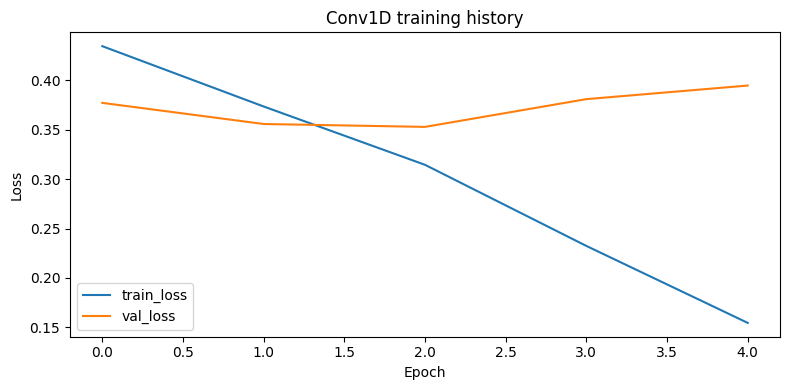

In [25]:
plot_history(conv_history, "Conv1D training history")

In [26]:
conv_val_prob = conv_model.predict(x_val, batch_size=BATCH_SIZE, verbose=0)
conv_test_prob = conv_model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)

conv_threshold, conv_val_micro_f1 = find_best_threshold(y_val, conv_val_prob)
conv_results = evaluate_predictions(y_test, conv_test_prob, conv_threshold)

print("Best validation threshold:", conv_threshold)
print("Best validation micro-F1:", round(conv_val_micro_f1, 4))
conv_results

Best validation threshold: 0.3
Best validation micro-F1: 0.49


{'threshold': np.float64(0.3),
 'micro_f1': 0.44897079426662356,
 'macro_f1': 0.335843153240618,
 'micro_precision': 0.45750054908851306,
 'macro_precision': 0.44209042840419877,
 'micro_recall': 0.44075327972915784,
 'macro_recall': 0.34363799615414337,
 'hamming_loss': 0.18111937654976976,
 'exact_match_accuracy': 0.11406305348919589}

## Conv1D model conclusion

The Conv1D model achieved a moderate result on the multi-label classification task. The best threshold on the validation set was 0.3, so a lower threshold worked better than the standard value of 0.5.

The test results show that the model performs better on frequent labels than on less common ones, because the micro-F1 score is clearly higher than the macro-F1 score. This means the model learned useful patterns, but its performance is still uneven across categories.

The validation loss improved in the beginning and then stopped improving, so the model was stopped early. In this case, early stopping was useful because training longer would probably lead to more overfitting.

## LSTM model

The second model uses LSTM layers.

I keep this model simple as well:
- the same vectorizer and embedding setup,
- one LSTM layer,
- one hidden dense layer,
- one sigmoid output layer.

I use the same loss function, callbacks, and evaluation procedure as for the Conv1D model. This keeps the comparison consistent.

## Why this LSTM model was chosen

 I kept the same text preprocessing pipeline as in the Conv1D model so that the comparison between both classical models would remain consistent.

The `Embedding` layer converts each text chunk into trainable vector representations. I use `Bidirectional(LSTM(64))` because LSTM models are designed for sequence data and can capture dependencies across the text, while the bidirectional version can use context from both directions. I chose 64 units as a moderate size that balances model capacity and training cost.

I added `Dropout(0.3)` to reduce overfitting. I then used one hidden `Dense(64)` layer to combine the learned sequence features before the final classification layer. This is a moderate intermediate size that keeps the model simple and comparable to the Conv1D baseline.

The final layer uses `sigmoid` because this is a multi-label classification task, so each label must be predicted independently.

In [17]:
lstm_model = keras.Sequential([
    layers.Input(shape=(), dtype=tf.string),
    vectorizer,
    layers.Embedding(vocab_size, EMBEDDING_DIM),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_labels, activation="sigmoid")
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 256)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 256, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,947,722 (15.06 MB)

 Trainable params: 3,947,722 (15.06 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
lstm_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    )
]

In [19]:
lstm_history = lstm_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=lstm_callbacks,
    verbose=1
)

Epoch 1/20
208/208 ━━━━━━━━━━━━━━━━━━━━ 28s 125ms/step - binary_accuracy: 0.8213 - loss: 0.4406 - precision: 0.4412 - recall: 0.1228 - val_binary_accuracy: 0.8494 - val_loss: 0.3909 - val_precision: 0.7143 - val_recall: 0.1522 - learning_rate: 0.0010
Epoch 2/20
208/208 ━━━━━━━━━━━━━━━━━━━━ 27s 127ms/step - binary_accuracy: 0.8476 - loss: 0.3788 - precision: 0.6852 - recall: 0.2202 - val_binary_accuracy: 0.8590 - val_loss: 0.3616 - val_precision: 0.7058 - val_recall: 0.2555 - learning_rate: 0.0010
Epoch 3/20
208/208 ━━━━━━━━━━━━━━━━━━━━ 29s 139ms/step - binary_accuracy: 0.8641 - loss: 0.3142 - precision: 0.7390 - recall: 0.3317 - val_binary_accuracy: 0.8556 - val_loss: 0.3771 - val_precision: 0.6278 - val_recall: 0.3161 - learning_rate: 0.0010
Epoch 4/20
208/208 ━━━━━━━━━━━━━━━━━━━━ 29s 137ms/step - binary_accuracy: 0.8883 - loss: 0.2511 - precision: 0.7647 - recall: 0.5116 - val_binary_accuracy: 0.8415 - val_loss: 0.4151 - val_precision: 0.5380 - val_recall: 0.3066 - learning_rate: 0.0

The model stopped early because `EarlyStopping` monitored validation loss and detected that the model was no longer improving on the validation set. Since validation loss became worse after the early epochs, continuing training would likely increase overfitting rather than improve performance.

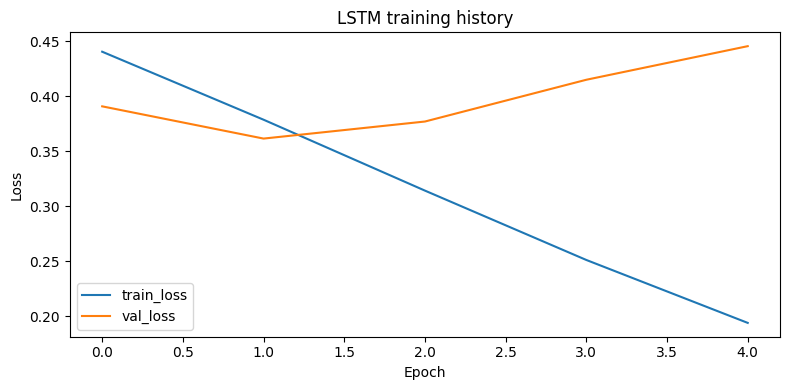

In [20]:
plot_history(lstm_history, "LSTM training history")

In [21]:
lstm_val_prob = lstm_model.predict(x_val, batch_size=BATCH_SIZE, verbose=0)
lstm_test_prob = lstm_model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)

lstm_threshold, lstm_val_micro_f1 = find_best_threshold(y_val, lstm_val_prob)
lstm_results = evaluate_predictions(y_test, lstm_test_prob, lstm_threshold)

print("Best validation threshold:", lstm_threshold)
print("Best validation micro-F1:", round(lstm_val_micro_f1, 4))
lstm_results

Best validation threshold: 0.3
Best validation micro-F1: 0.4505


{'threshold': np.float64(0.3),
 'micro_f1': 0.4241223726202267,
 'macro_f1': 0.2439604206790093,
 'micro_precision': 0.44187113047466176,
 'macro_precision': 0.39906638287663243,
 'micro_recall': 0.40774439272111723,
 'macro_recall': 0.29215293759307476,
 'hamming_loss': 0.18537017357421184,
 'exact_match_accuracy': 0.12185618136733971}

## Compare the two models

To compare the models, I focus on metrics that are suitable for multi-label classification.

The most important metrics here are:
- micro-F1, because it gives a balanced overall summary of performance across all predictions;
- macro-F1, because it shows how evenly the model performs across labels;
- hamming loss, because it measures the fraction of wrong label decisions;
- exact match accuracy as a stricter supplementary metric.

I do not rely only on binary accuracy, because in multi-label tasks it can look acceptable even when the model still misses important labels.

In [27]:
comparison_df = pd.DataFrame([
    {
        "model": "Conv1D",
        **conv_results
    },
    {
        "model": "LSTM",
        **lstm_results
    }
])

comparison_df

,model,threshold,micro_f1,macro_f1,micro_precision,macro_precision,micro_recall,macro_recall,hamming_loss,exact_match_accuracy
0,Conv1D,0.3,0.448971,0.335843,0.457501,0.442090,0.440753,0.343638,0.181119,0.114063
1,LSTM,0.3,0.424122,0.243960,0.441871,0.399066,0.407744,0.292153,0.185370,0.121856


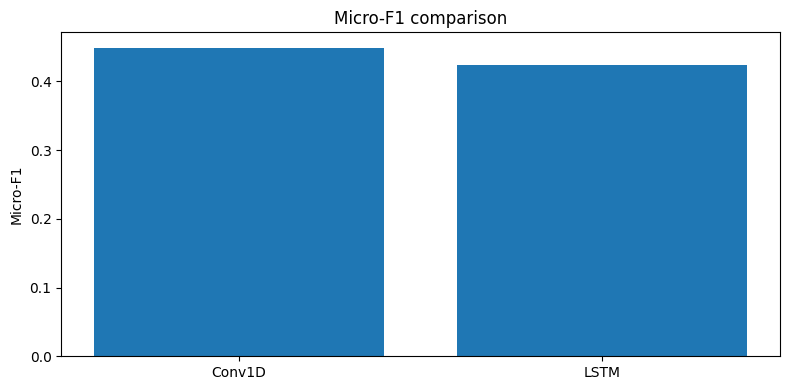

In [28]:
plt.figure(figsize=(8, 4))
plt.bar(comparison_df["model"], comparison_df["micro_f1"])
plt.title("Micro-F1 comparison")
plt.ylabel("Micro-F1")
plt.tight_layout()
plt.show()

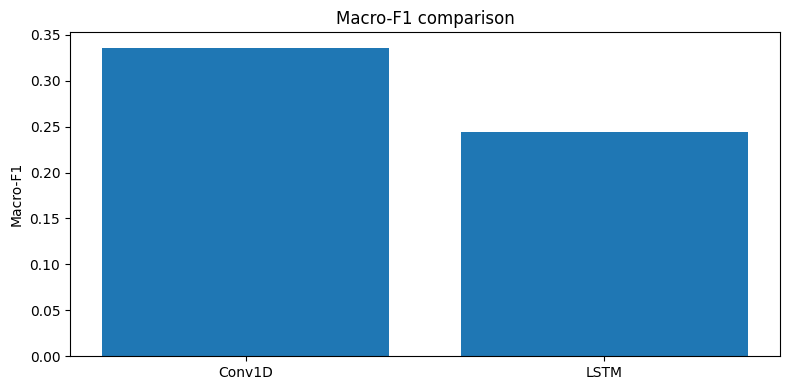

In [29]:
plt.figure(figsize=(8, 4))
plt.bar(comparison_df["model"], comparison_df["macro_f1"])
plt.title("Macro-F1 comparison")
plt.ylabel("Macro-F1")
plt.tight_layout()
plt.show()

## Comparison of the classical models

The Conv1D model performed better than the LSTM model on the main multi-label metrics. It achieved a higher micro-F1 (0.4490 vs. 0.4241) and a clearly higher macro-F1 (0.3358 vs. 0.2440). It also had a slightly lower hamming loss, which means it made fewer label-level errors overall.

Although the LSTM model reached a slightly higher exact match accuracy, this metric is very strict in multi-label classification and is less informative on its own than micro-F1, macro-F1, and hamming loss. For that reason, the overall comparison still favors the Conv1D model.

This suggests that, for this chunk-based Gutenberg dataset, local text patterns were more useful than longer sequential dependencies. The LSTM model still learned meaningful information, but it generalized less effectively and showed stronger signs of overfitting during training.

Overall, the Conv1D model is the stronger classical baseline for this task. 

In [ ]:
conv_model.save(MODEL_DIR / "conv1d_model.keras")
lstm_model.save(MODEL_DIR / "lstm_model.keras")